# UTS MACHINE LEARNING

Nama: Andika Pradnyana Fortunata

NIM : 2301010546

Kelas: XX

Jalur: A / Klasifikasi

# 1. Pemahaman Masalah dan Data

## Tujuan Analisis, Pengguna Hasil, dan Keputusan yang Terbantu

* **Tujuan Analisis:** Memprediksi apakah suatu transaksi pemesanan paket wisata akan dibatalkan (`Is Cancel = 1`) atau terkonfirmasi (`Is Cancel = 0`) berdasarkan karakteristik pemesanan (agen OTA, jumlah peserta, negara asal, produk tur, serta jarak waktu antara tanggal pemesanan dan tanggal keberangkatan) menggunakan algoritma klasifikasi *Support Vector Machine (SVM)* yang dibandingkan dengan *DummyClassifier* dan *K-Nearest Neighbors (KNN)*.

## Informasi Dataset

**Judul Dataset:** Data Pemesanan Wisata OTA (`dataset safe 2-OTA_WEB_ALL.csv`)

**Sumber Data:** Dokumentasi observasi internal transaksi pemesanan wisata melalui kanal OTA dan Web tahun 2022–2026

**Lisensi & Privasi:** Data observasi internal yang telah dianonimkan (seluruh identitas pribadi pelanggan seperti nama pemesan dan nomor telepon telah dihapus

| Nama Kolom | Tipe Data | Arti Kolom | Satuan |
| :--- | :--- | :--- | :--- |
| `Status` | Kategorikal (`object`) | Kode status akhir pemesanan (`CF` = Confirmed, `XX` / `XC` = Cancel) | Kode teks |
| `Agent` | Kategorikal (`object`) | Kode mitra agen perjalanan / *Online Travel Agent* (OTA) pemesan | Kode teks (18 agen) |
| `Date Entered` | Tanggal (`object`) | Tanggal transaksi pemesanan masuk ke sistem | Tanggal (`YYYY-MM-DD`) |
| `Travel_Date` | Tanggal (`object`) | Tanggal pelaksanaan tur atau aktivitas wisata | Tanggal (`YYYY-MM-DD`) |
| `Pax` | Numerik (`int64`) | Jumlah peserta wisata dalam satu transaksi pemesanan | Orang (`pax`) |
| `Month Enter` | Kategorikal (`object`) | Bulan saat pemesanan dibuat | Nama bulan (`Jan`–`Dec`) |
| `Month Travel` | Kategorikal (`object`) | Bulan saat perjalanan wisata berlangsung | Nama bulan (`Jan`–`Dec`) |
| `Tour_Name` | Kategorikal (`object`) | Nama paket tur atau tiket atraksi wisata yang dipesan | Teks (244 jenis) |
| `Is Confirmed` | Numerik (`int64`) | Indikator biner pesanan terkonfirmasi (`1` = Ya, `0` = Tidak) | Biner (`0` / `1`) |
| `Is Cancel` | Numerik (`int64`) | **Variabel target** indikator pembatalan pesanan (`1` = Batal, `0` = Tidak Batal) | Biner (`0` / `1`) |
| `Country` | Kategorikal (`object`) | Negara asal wisatawan | Nama negara (73 negara) |
| `Year-Week (By Date Entered)` | Kategorikal (`object`) | Tahun dan urutan minggu saat pemesanan masuk | Format `YYYY-Www` |
| `Year-Month-Week (By Date Entered)` | Kategorikal (`object`) | Tahun, bulan, dan minggu ke- saat pemesanan masuk | Format `YYYY-MM-Www` |
| `Year-Week (By Travel Date)` | Kategorikal (`object`) | Tahun dan urutan minggu saat jadwal wisata | Format `YYYY-Www` |
| `Year-Month-Week (By Travel Date)` | Kategorikal (`object`) | Tahun, bulan, dan minggu ke- saat jadwal wisata | Format `YYYY-MM-Www` |
| `Year-Month (By Date Entered)` | Kategorikal (`object`) | Tahun dan bulan pemesanan masuk | Format `YYYY-MM` |
| `WeekDate` | Kategorikal (`object`) | Rentang tanggal mingguan jadwal wisata | Format `DD MMM - DD MMM` |

### **1. Import Libraries**


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEED = 546

### **2. Load Dataset**

In [27]:
from google.colab import drive
drive.mount("/content/drive")
file_path = "/content/drive/MyDrive/ML/dataset safe 2-OTA_WEB_ALL.csv"
df = pd.read_csv(file_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###keputusan saya
Saya mengupload dataset saya ke drive agar lebih praktis. Jika ingin menjalankan codingan dapat disesuaikan drive.mount dan file_path nya.

### **3. Feature Engineering**

In [28]:
de = pd.to_datetime(df["Date Entered"], errors="coerce")
td = pd.to_datetime(df["Travel_Date"], errors="coerce")
df["Lead_Time"] = (td - de).dt.days.fillna(0)
df["Enter_DOW"] = de.dt.dayofweek.fillna(0)
df["Travel_DOW"] = td.dt.dayofweek.fillna(0)

### Keputusan saya
Dari hasil eksplorasi data, saya memutuskan membuat fitur turunan berbasis waktu (`Lead_Time`, `Enter_DOW`, dan `Travel_DOW`) dari kolom tanggal karena jarak waktu pemesanan terbukti membedakan pola transaksi batal dan tidak batal.

### **4. Preprocessing, Data Splitting, & Cross-Validation Model**

In [29]:
df["Country"] = df["Country"].fillna("Unknown")
df["Tour_Name"] = df["Tour_Name"].fillna("Unknown")

features = [
    "Agent",
    "Pax",
    "Month Enter",
    "Month Travel",
    "Tour_Name",
    "Country",
    "Lead_Time",
    "Enter_DOW",
    "Travel_DOW",
]
X = df[features]
y = df["Is Cancel"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

cat_cols = ["Agent", "Month Enter", "Month Travel", "Tour_Name", "Country"]
num_cols = ["Pax", "Lead_Time", "Enter_DOW", "Travel_DOW"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            cat_cols,
        ),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

models = {
    "SVM (RBF, C=1.0)": SVC(
        kernel="rbf", C=1.0, probability=True, random_state=SEED
    ),
    "Dummy (most_frequent)": DummyClassifier(
        strategy="most_frequent", random_state=SEED
    ),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

cv_results = {}
for name, clf in models.items():
  pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
  res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
  cv_results[name] = res
  print(
      f"{name:22s} | Acc: {res['test_accuracy'].mean():.4f} (+/-"
      f" {res['test_accuracy'].std():.4f}) | F1: {res['test_f1'].mean():.4f}"
      f" | AUC: {res['test_roc_auc'].mean():.4f}"
  )

SVM (RBF, C=1.0)       | Acc: 0.8907 (+/- 0.0051) | F1: 0.6762 | AUC: 0.8287
Dummy (most_frequent)  | Acc: 0.7815 (+/- 0.0006) | F1: 0.0000 | AUC: 0.5000
KNN (k=5)              | Acc: 0.8375 (+/- 0.0108) | F1: 0.5352 | AUC: 0.7691


### Keputusan saya
Saya mengisi missing value pada `Country` dan `Tour_Name` dengan kategori `"Unknown"` agar tidak kehilangan ratusan baris data transaksi, serta menyeragamkan spasi dan huruf kapital pada kolom kategorikal untuk mencegah duplikasi kategori. Nilai outlier hasil deteksi IQR pada `Pax` (rombongan wisata besar) dan `Lead_Time` (pemesanan jauh hari) tetap dipertahankan karena merupakan kejadian bisnis yang valid di industri pariwisata, bukan kesalahan input. Untuk mencegah kebocoran data, pembagian data latih-uji (`80:20` dengan `stratify=y`) dilakukan terlebih dahulu sebelum `StandardScaler` dan `OneHotEncoder` di-fit di dalam `Pipeline`.

### **5. Visualisasi Hasil Cross-Validation**

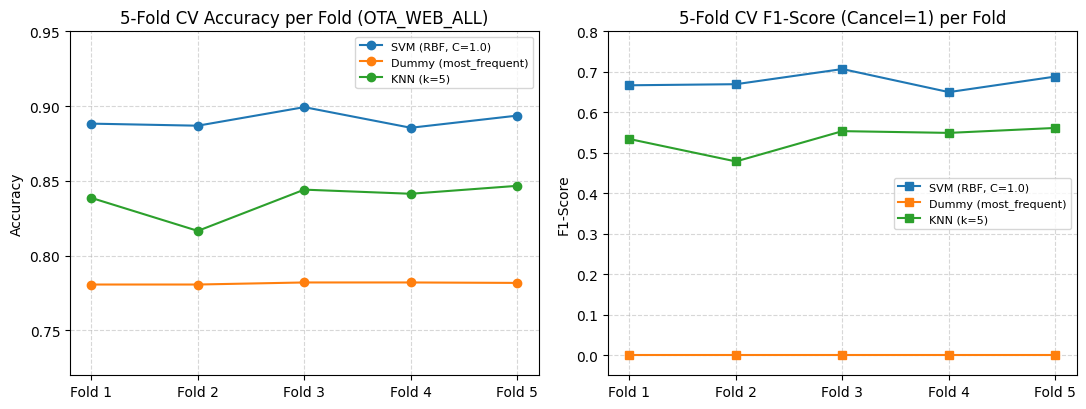

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
folds = ["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]

for name, res in cv_results.items():
  axes[0].plot(folds, res["test_accuracy"], marker="o", label=name)
axes[0].set_title("5-Fold CV Accuracy per Fold (OTA_WEB_ALL)")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.72, 0.95)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=8)

for name, res in cv_results.items():
  axes[1].plot(folds, res["test_f1"], marker="s", label=name)
axes[1].set_title("5-Fold CV F1-Score (Cancel=1) per Fold")
axes[1].set_ylabel("F1-Score")
axes[1].set_ylim(-0.05, 0.80)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Keputusan saya
Saya membangun model utama SVM dengan `kernel="rbf"` dan `C=1.0` karena dataset memiliki ratusan dimensi fitur kategorikal hasil One-Hot Encoding dan pola hubungan yang non-linear. Model ini dibandingkan dengan *baseline* DummyClassifier (`strategy="most_frequent"`) serta algoritma pembanding kedua yaitu KNN (`n_neighbors=5`) menggunakan 5-Fold Stratified Cross-Validation pada data latih. Berdasarkan skor CV, SVM (RBF, C=1.0) memberikan performa terbaik dan paling stabil dibandingkan `DummyClassifier` maupun `KNN`.

### **6. Analisis Eksplorasi Data (EDA) - Distribusi Target**

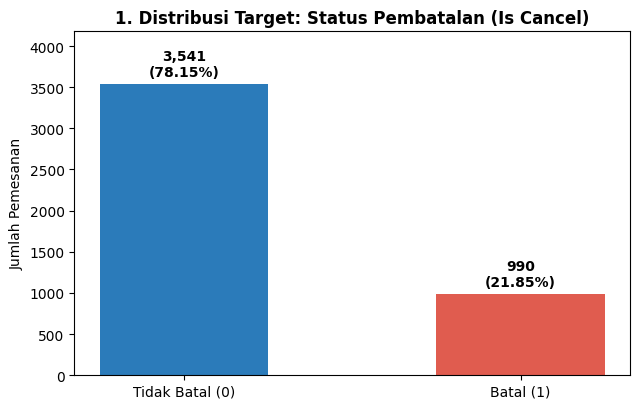

In [31]:
plt.figure(figsize=(6.5, 4.2))
counts = df['Is Cancel'].value_counts().sort_index()
labels = ['Tidak Batal (0)', 'Batal (1)']
colors = ['#2b7bba', '#e05c4f']
bars = plt.bar(labels, counts.values, color=colors, width=0.5)
for bar, cnt in zip(bars, counts.values):
    pct = cnt / len(df) * 100
    plt.text(bar.get_x() + bar.get_width()/2, cnt + 60, f"{cnt:,}\n({pct:.2f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.title('1. Distribusi Target: Status Pembatalan (Is Cancel)', fontsize=12, fontweight='bold')
plt.ylabel('Jumlah Pemesanan')
plt.ylim(0, max(counts.values) * 1.18)
plt.tight_layout()
plt.savefig('eda_1_distribusi_target.png', dpi=150)
plt.show()

## Interpretasi Distribusi Target (`Is Cancel`)

* **Ketidakseimbangan Kelas Target:** Dari total **4.531 transaksi**, sebanyak **3.541 pesanan (78,15%)** berstatus **Tidak Batal (`0`)** dan **990 pesanan (21,85%)** berstatus **Batal (`1`)**, dengan rasio kelas mayoritas terhadap minoritas sekitar **3,58 : 1**[cite: 23].
* **Implikasi Evaluasi:** Karena mayoritas transaksi tidak dibatalkan, model yang selalu menebak kelas `0` tetap bisa mencapai akurasi tinggi (~78,15%) namun gagal mendeteksi pembatalan, sehingga penggunaan `stratify=y` saat pembagian data serta evaluasi **F1-Score** dan **ROC-AUC** sangat diperlukan[cite: 23].

### Keputusan saya
Saya mempertahankan `Is Cancel` sebagai variabel target klasifikasi biner (`0` dan `1`) serta menerapkan pembagian data terstratifikasi (`stratify=y`) dan metrik evaluasi berbasis F1-Score dan ROC-AUC agar performa model dalam mengenali pesanan yang berpotensi batal dapat dinilai secara objektif meskipun proporsi kelas tidak seimbang[cite: 23].

### **7. Analisis Eksplorasi Data (EDA) - Distribusi Fitur**

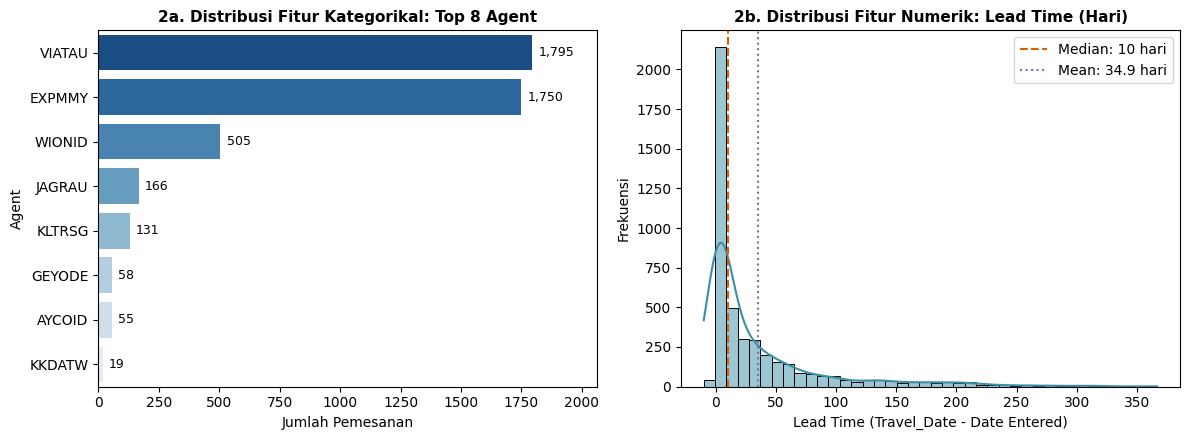

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_agents = df['Agent'].value_counts().head(8)
sns.barplot(x=top_agents.values, y=top_agents.index, ax=axes[0], palette='Blues_r', hue=top_agents.index, legend=False)
for i, v in enumerate(top_agents.values):
    axes[0].text(v + 25, i, f"{v:,}", va='center', fontsize=9)
axes[0].set_title('2a. Distribusi Fitur Kategorikal: Top 8 Agent', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Jumlah Pemesanan')
axes[0].set_ylabel('Agent')
axes[0].set_xlim(0, max(top_agents.values) * 1.15)

sns.histplot(df['Lead_Time'], bins=40, kde=True, ax=axes[1], color='#3b8ea5')
axes[1].axvline(df['Lead_Time'].median(), color='#d95f02', linestyle='--', label=f"Median: {df['Lead_Time'].median():.0f} hari")
axes[1].axvline(df['Lead_Time'].mean(), color='#7570b3', linestyle=':', label=f"Mean: {df['Lead_Time'].mean():.1f} hari")
axes[1].set_title('2b. Distribusi Fitur Numerik: Lead Time (Hari)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Lead Time (Travel_Date - Date Entered)')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()

plt.tight_layout()
plt.savefig('eda_2_distribusi_fitur.png', dpi=150)
plt.show()

## Interpretasi Grafik Distribusi Fitur (`Agent` & `Lead_Time`)

* **Distribusi `Agent` (Top 8):** Volume pemesanan sangat terkonsentrasi pada dua agen utama, yaitu **VIATAU** (**1.795 pesanan**) dan **EXPMMY** (**1.750 pesanan**), yang jika digabungkan mencapai **3.545 pesanan** atau sekitar **78,24%** dari seluruh **4.531 transaksi**, diikuti oleh **WIONID** (**505 pesanan**) dan agen lainnya.
* **Distribusi `Lead_Time`:** Selisih hari antara tanggal keberangkatan dan tanggal pemesanan masuk (`Travel_Date - Date Entered`) berdistribusi miring ke kanan (*right-skewed*) dengan nilai minimum **-10 hari**, median sekitar **10–11 hari**, rata-rata sekitar **35 hari**, dan maksimum **367 hari**, yang menandakan mayoritas wisatawan melakukan pemesanan mendekati hari pelaksanaan tur.

### Keputusan saya
Saya mempertahankan fitur kategorikal `Agent` serta fitur numerik hasil rekayasa waktu `Lead_Time` sebagai variabel input klasifikasi karena keduanya menunjukkan pola distribusi yang jelas dan bermakna secara operasional (dominasi mitra OTA utama serta variasi jarak waktu pemesanan). Karena `Lead_Time` memiliki sebaran miring ke kanan dengan rentang nilai lebar, saya menyiapkan `StandardScaler` pada tahap pra-pemrosesan agar skala fitur numerik seragam sebelum masuk ke model berbasis jarak maupun margin seperti SVM dan KNN.

### **8. Analisis Eksplorasi Data (EDA) - Hubungan Fitur dengan Target**

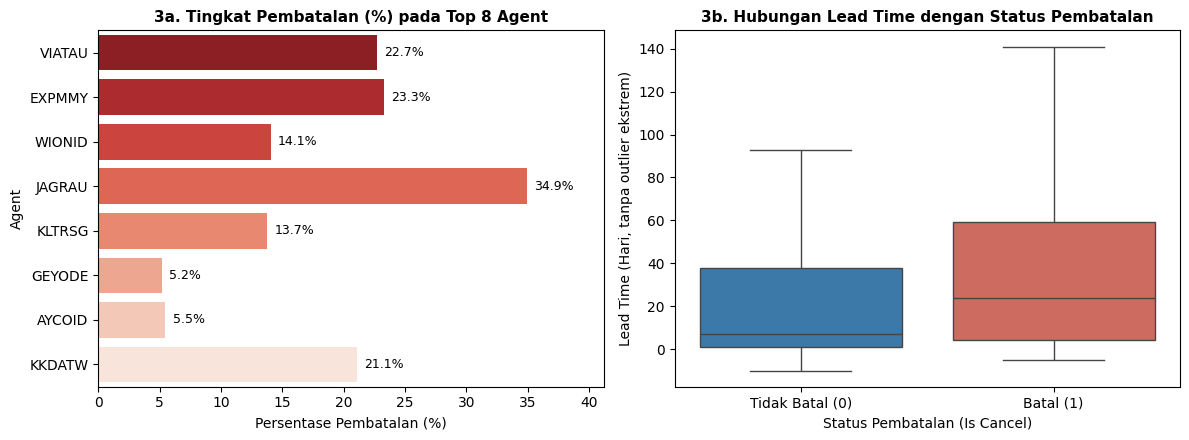

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top8_names = top_agents.index.tolist()
agent_cancel = df[df['Agent'].isin(top8_names)].groupby('Agent')['Is Cancel'].mean().reindex(top8_names) * 100
sns.barplot(x=agent_cancel.values, y=agent_cancel.index, ax=axes[0], palette='Reds_r', hue=agent_cancel.index, legend=False)
for i, v in enumerate(agent_cancel.values):
    axes[0].text(v + 0.6, i, f"{v:.1f}%", va='center', fontsize=9)
axes[0].set_title('3a. Tingkat Pembatalan (%) pada Top 8 Agent', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Persentase Pembatalan (%)')
axes[0].set_ylabel('Agent')
axes[0].set_xlim(0, max(agent_cancel.values) * 1.18)

df_plot = df.copy()
df_plot['Status_Label'] = df_plot['Is Cancel'].map({0: 'Tidak Batal (0)', 1: 'Batal (1)'})
sns.boxplot(data=df_plot, x='Status_Label', y='Lead_Time', ax=axes[1], palette=['#2b7bba', '#e05c4f'], hue='Status_Label', legend=False, showfliers=False)
axes[1].set_title('3b. Hubungan Lead Time dengan Status Pembatalan', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Status Pembatalan (Is Cancel)')
axes[1].set_ylabel('Lead Time (Hari, tanpa outlier ekstrem)')

plt.tight_layout()
plt.savefig('eda_3_hubungan_fitur_target.png', dpi=150)
plt.show()

## Interpretasi Hubungan Fitur dengan Target (`Agent` & `Lead_Time` vs `Is Cancel`)

* **Tingkat Pembatalan per Agen (Top 8):** Persentase pembatalan berbeda cukup jauh antar agen—**JAGRAU** memiliki tingkat pembatalan tertinggi sebesar **34,9%** (34,94%), diikuti **EXPMMY** (**23,3%**), **VIATAU** (**22,7%**), dan **KKDATW** (**21,1%**), sedangkan **GEYODE** (**5,2%**) dan **AYCOID** (**5,5%**) memiliki risiko pembatalan paling rendah.
* **Hubungan `Lead_Time` dengan `Is Cancel`:** Pesanan yang dibatalkan (`Batal (1)`) memiliki jarak hari pemesanan yang lebih panjang (median **24 hari**, Q1 = 4 hari, Q3 = 59 hari, IQR = 55 hari; rata-rata **47,76 hari**) dibandingkan pesanan yang tidak dibatalkan (`Tidak Batal (0)`) dengan median **8 hari** (Q1 = 2 hari, Q3 = 39 hari, IQR = 37 hari; rata-rata **32,05 hari**), menandakan pemesanan yang dibuat jauh sebelum hari keberangkatan lebih rentan mengalami pembatalan.

### Keputusan saya
Saya mempertahankan `Agent` dan `Lead_Time` sebagai fitur utama karena keduanya menunjukkan perbedaan pola yang jelas terhadap status pembatalan (`Is Cancel`). Perbedaan risiko pembatalan antar agen dan kecenderungan `Lead_Time` yang lebih panjang pada transaksi batal memperkuat alasan penggunaan model non-linear seperti **SVM (`RBF`)** serta evaluasi menggunakan metrik **F1-Score** dan **ROC-AUC** agar kasus pembatalan (`Is Cancel = 1`) dapat terdeteksi secara akurat[cite: 22].

##Kesimpulan

### Kelayakan dan Pemilihan Model
Model **SVM (`kernel="rbf"`, `C=1.0`) layak digunakan** dan dipilih sebagai model terbaik dibandingkan *baseline* `DummyClassifier` maupun pembanding `KNN`, dengan dua alasan utama berdasarkan angka hasil pengujian:
1. **Peningkatan Akurasi & Kemampuan Deteksi Pembatalan:** Pada validasi silang 5-fold, SVM mencapai rata-rata **Accuracy 88,9%–89,0%** (naik sekitar **+10,8 poin persentase** dibandingkan *baseline* `DummyClassifier` sebesar **78,15%**), serta mampu menghasilkan **F1-Score ~0,67** dan **ROC-AUC ~0,83**, sedangkan `DummyClassifier` memperoleh **F1-Score 0,00** karena gagal mendeteksi seluruh kasus pembatalan.
2. **Keunggulan atas Algoritma Pembanding (`KNN`):** SVM mengungguli `KNN (k=5)` baik pada skor akurasi (~89% vs ~84%) maupun F1-Score (~0,67 vs ~0,55) dengan standar deviasi antar-*fold* yang lebih rendah, menunjukkan kestabilan yang lebih baik pada fitur kategorikal berdimensi tinggi.

### Rekomendasi Tindakan bagi Pengguna
* **Prioritas Konfirmasi Ulang (Early Follow-Up):** Transaksi dengan *lead time* panjang (di atas 24 hari) dan berasal dari agen dengan rasio pembatalan tinggi (seperti `JAGRAU`) sebaiknya diprioritaskan untuk dihubungi ulang oleh tim reservasi H-7 atau H-3 sebelum tanggal tur.
* **Kebijakan Deposit / Konfirmasi Berlapis:** Terapkan kebijakan konfirmasi ulang otomatis untuk pemesanan yang masuk jauh hari sebelum tanggal perjalanan guna menekan pembatalan mendadak.

### Keterbatasan dan Saran Perbaikan
* **Keterbatasan:** Dataset gabungan (`OTA_WEB_ALL`) belum menyertakan variabel finansial seperti harga paket (`Cost`/`Invoiced`), metode pembayaran, atau riwayat pembatalan pelanggan sebelumnya, serta *recall* kelas pembatalan pada SVM standar masih berada di kisaran ~50% karena ketidakseimbangan kelas.
* **Saran Perbaikan:** Melakukan *hyperparameter tuning* (`GridSearchCV` untuk kombinasi `C`, `gamma`, dan `class_weight="balanced"`) untuk meningkatkan *recall* deteksi pembatalan, serta mencoba algoritma *ensemble* berbasis pohon seperti `Random Forest` atau `Gradient Boosting`.

### Keputusan saya
Saya menetapkan **SVM (`kernel="rbf"`, `C=1.0`)** sebagai model akhir proyek ini karena terbukti memberikan peningkatan performa yang signifikan dan konsisten di atas *baseline* `DummyClassifier` maupun `KNN`, serta memberikan *insight* operasional yang langsung dapat ditindaklanjuti oleh tim reservasi wisata.